# Lab02 - Klasyfikacja według tekstur, Macierze GLCM

### Pobieranie danych

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import tarfile

DATA_DIR = Path("data")
root = DATA_DIR / "KTH_TIPS"
archive = DATA_DIR / "kth_tips_grey_200x200.tar"
data_url = (
    "https://web.archive.org/web/20051104182407id_/"
    "http://www.nada.kth.se:80/cvap/databases/kth-tips/"
    "kth_tips_grey_200x200.tar"
)

if not root.is_dir():
    DATA_DIR.mkdir(exist_ok=True)
    if not archive.is_file():
        urlretrieve(data_url, archive)
    with tarfile.open(archive) as package:
        package.extractall(DATA_DIR, filter="data")

print("Folder danych:", root.resolve())

Folder danych: /Users/kamilbaran/Repositories/UMiSI/Sem 2/PatternRecognition/lab02/data/KTH_TIPS


In [2]:
from collections import Counter
from PIL import Image
import pandas as pd

files = sorted(root.rglob("*.png"))
df = pd.DataFrame({"path": files})
df["material"] = [p.parent.name for p in files]

print("Obrazów:", len(df))
print(df.groupby("material").size())

def header(p):
    with Image.open(p) as im:
        return im.size, im.mode

headers = [header(p) for p in files]
print("Tryby:", Counter(mode for size, mode in headers))
print("Najczęstszy rozmiar:", Counter(size for size, mode in headers).most_common(1))

Obrazów: 810
material
aluminium_foil    81
brown_bread       81
corduroy          81
cotton            81
cracker           81
linen             81
orange_peel       81
sandpaper         81
sponge            81
styrofoam         81
dtype: int64
Tryby: Counter({'L': 810})
Najczęstszy rozmiar: [((200, 200), 747)]


### Wczytywanie grayscale

In [3]:
import numpy as np
from skimage import io

def load_gray(p):
    return io.imread(p)

gray = load_gray(df["path"].iloc[0])
print(gray.shape, gray.dtype)

(200, 200) uint8


### Podgląd klas

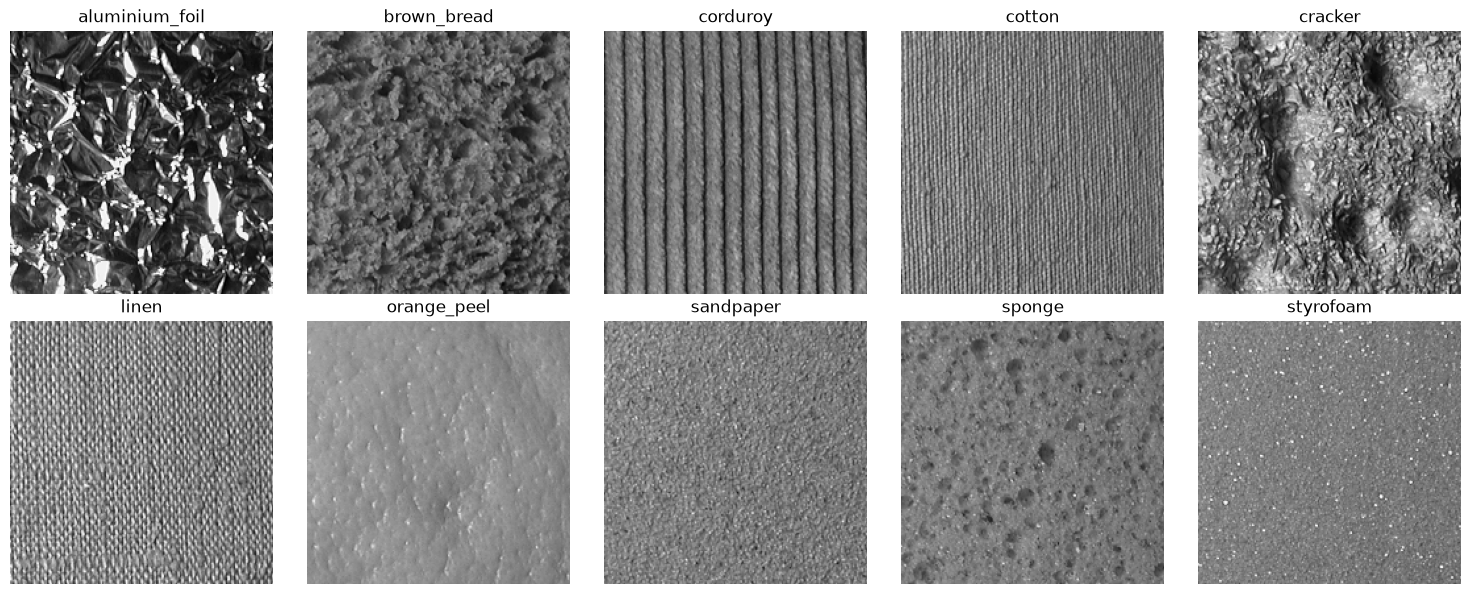

In [4]:
import matplotlib.pyplot as plt

materials = sorted(df["material"].unique())
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, material in zip(axes.flat, materials):
    paths_m = df.loc[df["material"] == material, "path"]
    ax.imshow(load_gray(paths_m.iloc[len(paths_m) // 2]), cmap="gray", vmin=0, vmax=255)
    ax.set_title(material)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Sprawdzenie bibliotek

In [5]:
import numpy as np
import pandas as pd
import mahotas
from mahotas.features.texture import haralick_labels
from skimage.feature import graycomatrix, graycoprops

matrix = np.array([[0, 0, 1, 1],
                [0, 0, 1, 1],
                [0, 2, 2, 2],
                [2, 2, 3, 3]], dtype=np.uint8)
angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]
angle_names = ["0 deg", "45 deg", "90 deg", "135 deg"]

P = graycomatrix(matrix, distances=[1], angles=angles, levels=4)
print(P[:, :, 0, 0])

P = graycomatrix(matrix, distances=[1], angles=angles, levels=4, symmetric=True, normed=True)
props = ["contrast", "homogeneity", "ASM", "energy", "correlation", "entropy"]
sk = pd.DataFrame({p: graycoprops(P, p)[0] for p in props}, index=angle_names)
display(sk.round(3))

H = mahotas.features.haralick(matrix)   # 4 kierunki × 13 cech
mh = pd.DataFrame(H, columns=haralick_labels[:13], index=angle_names)
display(mh[["Contrast", "Inverse Difference Moment", "Angular Second Moment",
            "Correlation", "Entropy"]].round(3))

[[2 2 1 0]
 [0 2 0 0]
 [0 0 3 1]
 [0 0 0 1]]


,contrast,homogeneity,ASM,energy,correlation,entropy
0 deg,0.583,0.808,0.146,0.382,0.720,2.095
45 deg,1.778,0.511,0.117,0.342,0.163,2.216
90 deg,1.000,0.700,0.139,0.373,0.486,2.095
135 deg,0.444,0.778,0.148,0.385,0.735,2.043


,Contrast,Inverse Difference Moment,Angular Second Moment,Correlation,Entropy
0 deg,0.583,0.808,0.146,0.720,3.022
45 deg,1.778,0.511,0.117,0.163,3.197
90 deg,1.000,0.700,0.139,0.486,3.022
135 deg,0.444,0.778,0.148,0.735,2.948


## Klasyfikacja

In [6]:
from sklearn.model_selection import train_test_split

CLASSES = ["aluminium_foil", "brown_bread", "corduroy", "cotton", "orange_peel"]
sub = df[df["material"].isin(CLASSES)].reset_index(drop=True)

train_df, test_df = train_test_split(
    sub,
    test_size=0.25,
    stratify=sub["material"],
    random_state=42,
)

display(pd.DataFrame({
    "trening": train_df["material"].value_counts(),
    "test": test_df["material"].value_counts(),
}).reindex(CLASSES))
print("Trening:", len(train_df), "| test:", len(test_df))

,trening,test
material,,
aluminium_foil,60,21
brown_bread,61,20
corduroy,61,20
cotton,60,21
orange_peel,61,20


Trening: 303 | test: 102


### Cechy GLCM

In [7]:
LEVELS = 16
DISTANCES = [1, 2, 4]
ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
PROPS = ["contrast", "homogeneity", "energy", "correlation", "entropy"]

def glcm_features(img):
    q = img // (256 // LEVELS)
    P = graycomatrix(
        q, distances=DISTANCES, angles=ANGLES,
        levels=LEVELS, symmetric=True, normed=True,
    )
    features = {}
    for prop in PROPS:
        values = graycoprops(P, prop).mean(axis=1)
        for distance, value in zip(DISTANCES, values):
            features[f"{prop}_d{distance}"] = value
    return features

feats_train = pd.DataFrame([glcm_features(load_gray(p)) for p in train_df["path"]])
feats_test = pd.DataFrame([glcm_features(load_gray(p)) for p in test_df["path"]])

X_train = feats_train.to_numpy()
X_test = feats_test.to_numpy()
y_train = train_df["material"].to_numpy()
y_test = test_df["material"].to_numpy()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
display(feats_train.groupby(y_train).mean().T.round(3))

X_train: (303, 15) | X_test: (102, 15)


,aluminium_foil,brown_bread,corduroy,cotton,orange_peel
contrast_d1,11.865,1.847,2.310,2.861,0.621
contrast_d2,17.398,2.728,3.276,3.550,0.827
contrast_d4,30.622,4.895,5.340,3.500,1.244
homogeneity_d1,0.521,0.632,0.618,0.570,0.800
homogeneity_d2,0.463,0.573,0.566,0.547,0.766
homogeneity_d4,0.342,0.464,0.463,0.551,0.697
energy_d1,0.186,0.224,0.239,0.304,0.392
energy_d2,0.169,0.208,0.224,0.299,0.374
energy_d4,0.137,0.185,0.202,0.297,0.341
correlation_d1,0.739,0.717,0.674,0.284,0.765


Energia vs entropia

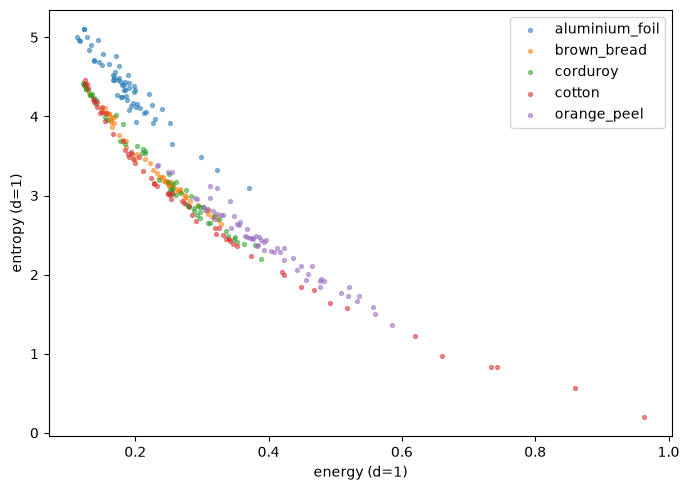

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for material in CLASSES:
    mask = y_train == material
    ax.scatter(
        feats_train.loc[mask, "energy_d1"],
        feats_train.loc[mask, "entropy_d1"],
        s=8, alpha=0.5, label=material,
    )
ax.set_xlabel("energy (d=1)")
ax.set_ylabel("entropy (d=1)")
ax.legend()
plt.tight_layout()
plt.show()

### KNN

Accuracy: 0.833 (83.3%)
Poprawne predykcje: 85 / 102


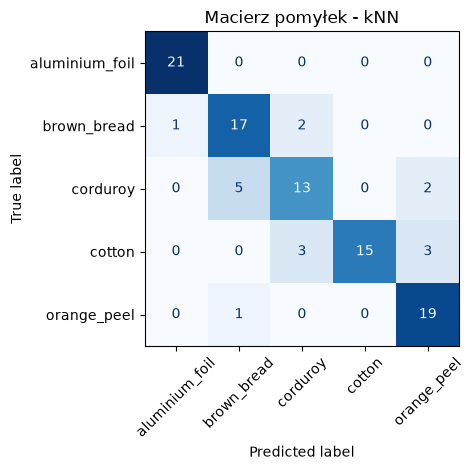

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f} ({accuracy:.1%})")
print(f"Poprawne predykcje: {(y_pred == y_test).sum()} / {len(y_test)}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=CLASSES, xticks_rotation=45,
    cmap="Blues", colorbar=False,
)
plt.title("Macierz pomyłek - kNN")
plt.tight_layout()
plt.show()

## Segmentacja

Proponuję przesuwać po obrazie okno 32 × 32 piksele ze skokiem 8 pikseli. Dla każdego okna obliczyłbym cechy funkcją `glcm_features()` i przewidział klasę za pomocą pipeline'u kNN. Etykietę piksela wyznaczyłbym przez głosowanie obejmujących go okien. Małe okno pozwala dokładniej wyznaczyć granice, ale daje mniej par do oszacowania GLCM. Duże okno daje stabilniejszy opis, lecz może obejmować różne tekstury. Ponieważ klasyfikator uczono na całych zdjęciach, do segmentacji dopasowałbym go na oknach z obrazów treningowych. Podział trening/test wykonałbym przed wycinaniem okien.

## Macierze GLRLM

GLRLM zlicza maksymalne serie kolejnych pikseli o tej samej skwantowanej jasności w wybranym kierunku. Element macierzy opisuje liczbę serii o danej jasności i długości. Na przykład wiersz `[0, 0, 0, 1, 1, 0]` zawiera serie: `000`, `11` oraz `0`. GLCM opisuje pary jasności w ustalonym przesunięciu, natomiast GLRLM opisuje długości jednolitych ciągów. Przykładowe cechy GLRLM to SRE, podkreślające krótkie serie, i LRE, podkreślające długie serie. W obu metodach istotne są kwantyzacja i kierunek.

## Sieci konwolucyjne?

Contrast GLCM można odtworzyć, stosując do skwantowanego obrazu filtr różnicowy, np. `[-1, 1]`, następnie podnosząc różnice do kwadratu i obliczając średnią. Sama liniowa konwolucja nie wykonuje więc całego obliczenia. Homogeneity wymaga dodatkowo nieliniowej funkcji różnic, a correlation także momentów i normalizacji. Dokładne obliczenie energy oraz entropy wymaga zliczenia par jasności i przekształcenia ich częstości. Cechy GLRLM wymagają rozpoznania początków, końców i długości maksymalnych serii; mały filtr nie obejmie dowolnie długiej serii. CNN z nieliniowościami i odpowiednim polem widzenia może nauczyć się przybliżeń takich zależności. Nie oznacza to automatycznego obliczania dokładnie tych samych współczynników. Ręczne cechy mogą dostarczyć dodatkowy, jawny opis tekstury, ale ich dołączenie nie gwarantuje poprawy klasyfikacji.